# TỐI ƯU HÓA KIẾN TRÚC MẠNG MLP BẰNG GIẢI THUẬT DI TRUYỀN (GENETIC ALGORITHM) CHO BÀI TOÁN CẢNH BÁO CHÁY IoT

Dự án này ứng dụng **Giải thuật di truyền (Genetic Algorithm - GA)** để tự động tìm kiếm kiến trúc mạng nơ-ron nhiều tầng (**Multi-Layer Perceptron - MLP**) tối ưu nhất cho bài toán phân loại cảnh báo cháy dựa trên dữ liệu cảm biến IoT (`smoke_detection_iot.csv`).

---

### **Quy trình thực hiện:**
1. **Kiểm tra phần cứng GPU**: Kích hoạt và xác nhận tăng tốc tính toán trên GPU NVIDIA GeForce RTX 4060 Laptop (CUDA).
2. **Tiền xử lý dữ liệu IoT**:
   - Loại bỏ các trường gây rò rỉ dữ liệu hoặc không mang giá trị phân loại (`Unnamed: 0`, `UTC`, `CNT`).
   - Phân chia tập dữ liệu thành **Train (70%)**, **Validation (15%)**, và **Test (15%)** với cơ chế phân tầng (Stratified Split).
   - Chuẩn hóa thang đo đặc trưng bằng `StandardScaler`.
3. **Không gian tìm kiếm di truyền (Gene Search Space) & Mạng MLP động (DynamicMLP)**:
   - Số tầng ẩn (Hidden Layers): 1 đến 4 tầng.
   - Số nơ-ron mỗi tầng ẩn: từ 16 đến 512 nơ-ron.
   - Hàm kích hoạt (Activation): ReLU, LeakyReLU, GELU, ELU.
   - Tỉ lệ Dropout: 0.0 đến 0.4.
   - Batch Normalization: Bật/Tắt.
   - Thuật toán tối ưu: Adam, AdamW, RMSprop.
   - Tốc độ học (Learning Rate): 0.0005, 0.001, 0.003, 0.005.
   - Trọng số suy giảm (Weight Decay): 0.0, 1e-4, 1e-3.
   - Kích thước Batch: 256, 512.
4. **Giải thuật di truyền (Genetic Algorithm)**:
   - **Fitness Function**: Kết hợp $0.6 \times F_1\text{-Score} + 0.4 \times \text{Accuracy}$ trên tập Validation (ưu tiên F1-score để giảm thiểu cảnh báo trượt và báo động giả).
   - **Tournament Selection** ($k=3$): Chọn lọc các cá thể tốt nhất để làm bố mẹ.
   - **Uniform Crossover**: Lai ghép trao đổi gen ngẫu nhiên.
   - **Gene Mutation**: Đột biến gen ngẫu nhiên để duy trì tính đa dạng của quần thể.
   - **Elitism**: Bảo tồn cá thể tinh hoa nhất qua từng thế hệ.
5. **Huấn luyện mô hình tối ưu (Full Retraining)**:
   - Huấn luyện lại mô hình tốt nhất với số epoch đầy đủ, cơ chế Early Stopping và Learning Rate Scheduler (`ReduceLROnPlateau`).
   - Lưu trữ trọng số mô hình tốt nhất (`best_mlp_fire_alarm.pt`).
6. **Đánh giá và Trực quan hóa Metrics toàn diện**:
   - Báo cáo phân loại chi tiết (Accuracy, Precision, Recall, F1, Specificity, ROC-AUC, PR-AUC).
   - Trực quan hóa Dashboard 6 đồ thị: Đường tiến hóa GA, Đường cong Loss, Đường cong Accuracy, Ma trận nhầm lẫn (Confusion Matrix), Đường cong ROC-AUC, Biểu đồ cột tổng hợp các chỉ số.

In [1]:
%matplotlib inline
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    precision_recall_curve, average_precision_score
)

# Cố định random seed để đảm bảo tính tái lập (Reproducibility)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True

# Kiểm tra và cấu hình thiết bị GPU CUDA
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("=" * 70)
print(f"PyTorch Version   : {torch.__version__}")
print(f"Thiết bị sử dụng  : {device}")
if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    print(f"Card đồ họa (GPU) : {gpu_name}")
    print(f"Dung lượng VRAM   : {gpu_mem:.2f} GB")
    print(f"Compute Capability: {torch.cuda.get_device_capability(0)}")
else:
    print("CẢNH BÁO: Không phát hiện GPU CUDA, đang chạy trên CPU!")
print("=" * 70)

PyTorch Version   : 2.6.0+cu124
Thiết bị sử dụng  : cuda
Card đồ họa (GPU) : NVIDIA GeForce RTX 4060 Laptop GPU
Dung lượng VRAM   : 8.00 GB
Compute Capability: (8, 9)


## 1. Nạp và tiền xử lý dữ liệu cảm biến IoT

In [2]:
# Nạp tập dữ liệu cảm biến cảnh báo cháy IoT
csv_file = 'smoke_detection_iot.csv'
if not os.path.exists(csv_file):
    import zipfile
    with zipfile.ZipFile('archive.zip', 'r') as z:
        z.extractall('.')

df = pd.read_csv(csv_file)
print(f"Kích thước tập dữ liệu ban đầu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print()
print("5 dòng dữ liệu đầu tiên:")
display(df.head())

# Tiền xử lý: Loại bỏ các cột không dùng làm đặc trưng dự đoán hoặc gây rò rỉ dữ liệu
cols_to_drop = ['Unnamed: 0', 'UTC', 'CNT']
df_clean = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

# Kiểm tra và loại bỏ các dòng bị trùng lặp nếu có
num_duplicates = df_clean.duplicated().sum()
if num_duplicates > 0:
    print(f"Loại bỏ {num_duplicates} dòng bị trùng lặp.")
    df_clean = df_clean.drop_duplicates()

print()
print(f"Kích thước sau khi làm sạch: {df_clean.shape[0]:,} dòng, {df_clean.shape[1]} cột")
print(f"Tổng số giá trị khuyết thiếu (Missing/NaN): {df_clean.isnull().sum().sum()}")

# Thống kê phân bố lớp mục tiêu 'Fire Alarm'
target_counts = df_clean['Fire Alarm'].value_counts()
target_pct = df_clean['Fire Alarm'].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({
    'Số lượng mẫu': target_counts,
    'Tỉ lệ (%)': target_pct.round(2)
})
target_summary.index = ['Có Cháy (1)' if idx == 1 else 'Không Cháy (0)' for idx in target_summary.index]
print()
print("Phân phối nhãn mục tiêu 'Fire Alarm':")
display(target_summary)

Kích thước tập dữ liệu ban đầu: 62,630 dòng, 16 cột

5 dòng dữ liệu đầu tiên:


,Unnamed: 0,UTC,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,CNT,Fire Alarm
0,0,1654733331,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0,0
1,1,1654733332,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,1,0
2,2,1654733333,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,2,0
3,3,1654733334,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,3,0
4,4,1654733335,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,4,0


Loại bỏ 2 dòng bị trùng lặp.

Kích thước sau khi làm sạch: 62,628 dòng, 13 cột
Tổng số giá trị khuyết thiếu (Missing/NaN): 0

Phân phối nhãn mục tiêu 'Fire Alarm':


,Số lượng mẫu,Tỉ lệ (%)
Có Cháy (1),44757,71.46
Không Cháy (0),17871,28.54


## 2. Phân chia tập dữ liệu & Chuẩn hóa thang đo (StandardScaler)

In [3]:
# Tách biến đặc trưng đầu vào (X) và biến mục tiêu (y)
target_col = 'Fire Alarm'
feature_cols = [c for c in df_clean.columns if c != target_col]

X = df_clean[feature_cols].values
y = df_clean[target_col].values

# Phân chia dữ liệu: 70% Train, 15% Validation (đánh giá GA), 15% Test (kiểm tra cuối cùng)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

# Chuẩn hóa đặc trưng bằng StandardScaler (chỉ fit trên tập Train để tránh Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("=" * 60)
print(f"Số lượng đặc trưng đầu vào (Features)  : {len(feature_cols)}")
print(f"Danh sách đặc trưng                     : {feature_cols}")
print(f"Tập Huấn luyện (Train Set)             : {X_train_scaled.shape[0]:,} mẫu ({X_train_scaled.shape[0]/len(df_clean)*100:.1f}%)")
print(f"Tập Đánh giá GA (Validation Set)       : {X_val_scaled.shape[0]:,} mẫu ({X_val_scaled.shape[0]/len(df_clean)*100:.1f}%)")
print(f"Tập Kiểm tra độc lập (Test Set)        : {X_test_scaled.shape[0]:,} mẫu ({X_test_scaled.shape[0]/len(df_clean)*100:.1f}%)")
print("=" * 60)

# Chuyển đổi dữ liệu sang định dạng PyTorch Tensor
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

Số lượng đặc trưng đầu vào (Features)  : 12
Danh sách đặc trưng                     : ['Temperature[C]', 'Humidity[%]', 'TVOC[ppb]', 'eCO2[ppm]', 'Raw H2', 'Raw Ethanol', 'Pressure[hPa]', 'PM1.0', 'PM2.5', 'NC0.5', 'NC1.0', 'NC2.5']
Tập Huấn luyện (Train Set)             : 43,839 mẫu (70.0%)
Tập Đánh giá GA (Validation Set)       : 9,394 mẫu (15.0%)
Tập Kiểm tra độc lập (Test Set)        : 9,395 mẫu (15.0%)


## 3. Không gian tìm kiếm di truyền & Mô hình MLP động (DynamicMLP)

In [4]:
# Không gian tìm kiếm kiến trúc mạng nơ-ron (Gene Search Space) cho Giải thuật di truyền
PARAM_SPACE = {
    'num_layers': [1, 2, 3, 4],
    'hidden_units_1': [32, 64, 128, 256, 512],
    'hidden_units_2': [16, 32, 64, 128, 256],
    'hidden_units_3': [16, 32, 64, 128],
    'hidden_units_4': [8, 16, 32, 64],
    'activation': ['relu', 'leaky_relu', 'gelu', 'elu'],
    'dropout': [0.0, 0.1, 0.2, 0.3, 0.4],
    'batch_norm': [True, False],
    'lr': [0.0005, 0.001, 0.003, 0.005],
    'optimizer': ['adam', 'adamw', 'rmsprop'],
    'weight_decay': [0.0, 1e-4, 1e-3],
    'batch_size': [256, 512]
}

def get_activation_layer(name):
    if name == 'relu':
        return nn.ReLU()
    elif name == 'leaky_relu':
        return nn.LeakyReLU(negative_slope=0.1)
    elif name == 'gelu':
        return nn.GELU()
    elif name == 'elu':
        return nn.ELU()
    return nn.ReLU()

class DynamicMLP(nn.Module):
    def __init__(self, input_dim, chromosome, num_classes=2):
        super(DynamicMLP, self).__init__()
        num_layers = chromosome['num_layers']
        act_name = chromosome['activation']
        use_bn = chromosome['batch_norm']
        dropout_rate = chromosome['dropout']
        
        layers = []
        current_dim = input_dim
        
        for i in range(1, num_layers + 1):
            out_dim = chromosome[f'hidden_units_{i}']
            layers.append(nn.Linear(current_dim, out_dim))
            if use_bn:
                layers.append(nn.BatchNorm1d(out_dim))
            layers.append(get_activation_layer(act_name))
            if dropout_rate > 0.0:
                layers.append(nn.Dropout(dropout_rate))
            current_dim = out_dim
            
        layers.append(nn.Linear(current_dim, num_classes))
        self.network = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.network(x)

def count_trainable_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

sample_chromosome = {gene: random.choice(vals) for gene, vals in PARAM_SPACE.items()}
sample_model = DynamicMLP(input_dim=len(feature_cols), chromosome=sample_chromosome).to(device)
print("Thử nghiệm khởi tạo mô hình DynamicMLP ngẫu nhiên trên GPU:")
print(f"Cấu hình cá thể (Chromosome): {sample_chromosome}")
print(f"Tổng số tham số học được: {count_trainable_params(sample_model):,}")
print()
print("Kiến trúc chi tiết:")
print(sample_model)

Thử nghiệm khởi tạo mô hình DynamicMLP ngẫu nhiên trên GPU:
Cấu hình cá thể (Chromosome): {'num_layers': 1, 'hidden_units_1': 32, 'hidden_units_2': 64, 'hidden_units_3': 32, 'hidden_units_4': 16, 'activation': 'leaky_relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.005, 'optimizer': 'adam', 'weight_decay': 0.0, 'batch_size': 256}
Tổng số tham số học được: 546

Kiến trúc chi tiết:
DynamicMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Linear(in_features=32, out_features=2, bias=True)
  )
)


## 4. Hàm đánh giá độ thích nghi (Fitness Function) trên GPU

In [5]:
def evaluate_chromosome(chromosome, X_train_t, y_train_t, X_val_t, y_val_t, epochs=5, device=device):
    batch_size = chromosome['batch_size']
    train_loader = DataLoader(
        TensorDataset(X_train_t, y_train_t),
        batch_size=batch_size,
        shuffle=True,
        drop_last=False
    )
    val_loader = DataLoader(
        TensorDataset(X_val_t, y_val_t),
        batch_size=1024,
        shuffle=False
    )
    
    input_dim = X_train_t.shape[1]
    model = DynamicMLP(input_dim=input_dim, chromosome=chromosome).to(device)
    criterion = nn.CrossEntropyLoss()
    
    lr = chromosome['lr']
    wd = chromosome['weight_decay']
    opt_type = chromosome['optimizer']
    if opt_type == 'adam':
        optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    elif opt_type == 'adamw':
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    elif opt_type == 'rmsprop':
        optimizer = optim.RMSprop(model.parameters(), lr=lr, weight_decay=wd)
    else:
        optimizer = optim.Adam(model.parameters(), lr=lr)
        
    for epoch in range(epochs):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            outputs = model(bx)
            loss = criterion(outputs, by)
            loss.backward()
            optimizer.step()
            
    model.eval()
    val_preds = []
    val_targets = []
    with torch.no_grad():
        for bx, by in val_loader:
            bx = bx.to(device)
            outputs = model(bx)
            preds = outputs.argmax(dim=1).cpu().numpy()
            val_preds.extend(preds)
            val_targets.extend(by.numpy())
            
    val_preds = np.array(val_preds)
    val_targets = np.array(val_targets)
    
    acc = accuracy_score(val_targets, val_preds)
    f1 = f1_score(val_targets, val_preds, zero_division=0)
    rec = recall_score(val_targets, val_preds, zero_division=0)
    prec = precision_score(val_targets, val_preds, zero_division=0)
    
    # Fitness kết hợp F1 (0.6) và Accuracy (0.4)
    fitness = 0.6 * f1 + 0.4 * acc
    
    del model, optimizer, train_loader, val_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        
    return fitness, acc, f1, rec, prec

## 5. Cài đặt Giải thuật di truyền (Genetic Algorithm)

In [6]:
class GeneticAlgorithmMLP:
    def __init__(self, param_space, pop_size=12, generations=6, p_crossover=0.8, p_mutation=0.25, elitism=2):
        self.param_space = param_space
        self.pop_size = pop_size
        self.generations = generations
        self.p_crossover = p_crossover
        self.p_mutation = p_mutation
        self.elitism = elitism
        
        self.population = []
        self.history = {
            'best_fitness': [],
            'avg_fitness': [],
            'worst_fitness': [],
            'best_accuracy': [],
            'best_f1': [],
            'best_recall': [],
            'best_precision': [],
            'best_chromosomes': []
        }
        self.best_overall_individual = None
        self.best_overall_fitness = -1.0
        
    def random_chromosome(self):
        return {gene: random.choice(vals) for gene, vals in self.param_space.items()}
        
    def initialize_population(self):
        self.population = [self.random_chromosome() for _ in range(self.pop_size)]
        
    def tournament_selection(self, population, fitnesses, k=3):
        candidate_indices = random.sample(range(len(population)), k)
        winner_idx = max(candidate_indices, key=lambda idx: fitnesses[idx])
        return copy.deepcopy(population[winner_idx])
        
    def uniform_crossover(self, parent1, parent2):
        if random.random() > self.p_crossover:
            return copy.deepcopy(parent1), copy.deepcopy(parent2)
            
        child1 = copy.deepcopy(parent1)
        child2 = copy.deepcopy(parent2)
        
        for gene in self.param_space.keys():
            if random.random() < 0.5:
                child1[gene], child2[gene] = child2[gene], child1[gene]
                
        return child1, child2
        
    def mutate(self, individual):
        mutated = copy.deepcopy(individual)
        for gene, vals in self.param_space.items():
            if random.random() < self.p_mutation:
                mutated[gene] = random.choice(vals)
        return mutated
        
    def run(self, X_train_t, y_train_t, X_val_t, y_val_t, eval_epochs=5):
        self.initialize_population()
        print("=" * 80)
        print("BẮT ĐẦU QUÁ TRÌNH TỐI ƯU KIẾN TRÚC MẠNG MLP BẰNG GENETIC ALGORITHM (GA)")
        print(f"Kích thước quần thể: {self.pop_size} cá thể | Số thế hệ: {self.generations}")
        print(f"Xác suất lai ghép   : {self.p_crossover} | Xác suất đột biến: {self.p_mutation} | Elitism: {self.elitism}")
        print(f"Thiết bị tính toán  : {device}")
        print("=" * 80)
        
        ga_start_time = time.time()
        
        for gen in range(1, self.generations + 1):
            gen_start_time = time.time()
            print()
            print(f">>> THẾ HỆ [{gen:02d}/{self.generations:02d}] - Đang đánh giá {self.pop_size} cá thể trên GPU...")
            
            fitnesses = []
            detailed_metrics = []
            
            for ind_idx, ind in enumerate(self.population):
                fit, acc, f1, rec, prec = evaluate_chromosome(
                    ind, X_train_t, y_train_t, X_val_t, y_val_t, epochs=eval_epochs, device=device
                )
                fitnesses.append(fit)
                detailed_metrics.append((acc, f1, rec, prec))
                
            fitnesses = np.array(fitnesses)
            best_idx = int(np.argmax(fitnesses))
            worst_idx = int(np.argmin(fitnesses))
            
            best_fit = float(fitnesses[best_idx])
            avg_fit = float(np.mean(fitnesses))
            worst_fit = float(fitnesses[worst_idx])
            best_acc, best_f1, best_rec, best_prec = detailed_metrics[best_idx]
            
            self.history['best_fitness'].append(best_fit)
            self.history['avg_fitness'].append(avg_fit)
            self.history['worst_fitness'].append(worst_fit)
            self.history['best_accuracy'].append(best_acc)
            self.history['best_f1'].append(best_f1)
            self.history['best_recall'].append(best_rec)
            self.history['best_precision'].append(best_prec)
            self.history['best_chromosomes'].append(copy.deepcopy(self.population[best_idx]))
            
            if best_fit > self.best_overall_fitness:
                self.best_overall_fitness = best_fit
                self.best_overall_individual = copy.deepcopy(self.population[best_idx])
                
            gen_duration = time.time() - gen_start_time
            print(f"    + Tốt nhất Gen {gen:02d}: Fitness = {best_fit:.4f} | Accuracy = {best_acc*100:.2f}% | F1-Score = {best_f1*100:.2f}%")
            print(f"    + Trung bình quần thể: Fitness = {avg_fit:.4f} | Kém nhất: {worst_fit:.4f}")
            print(f"    + Thời gian thế hệ    : {gen_duration:.2f} giây")
            print(f"    + Cấu hình tốt nhất   : {self.population[best_idx]}")
            
            if gen < self.generations:
                sorted_indices = np.argsort(fitnesses)[::-1]
                next_gen = [copy.deepcopy(self.population[idx]) for idx in sorted_indices[:self.elitism]]
                
                while len(next_gen) < self.pop_size:
                    parent1 = self.tournament_selection(self.population, fitnesses)
                    parent2 = self.tournament_selection(self.population, fitnesses)
                    child1, child2 = self.uniform_crossover(parent1, parent2)
                    child1 = self.mutate(child1)
                    child2 = self.mutate(child2)
                    
                    next_gen.append(child1)
                    if len(next_gen) < self.pop_size:
                        next_gen.append(child2)
                        
                self.population = next_gen
                
        total_ga_duration = time.time() - ga_start_time
        print()
        print("=" * 80)
        print(f"HOÀN TẤT GIẢI THUẬT DI TRUYỀN TRONG {total_ga_duration:.2f} GIÂY!")
        print(f"Fitness tốt nhất tìm được: {self.best_overall_fitness:.4f}")
        print("KIẾN TRÚC MẠNG MLP TỐI ƯU NHẤT (BEST INDIVIDUAL):")
        for k, v in self.best_overall_individual.items():
            print(f"   * {k:<15}: {v}")
        print("=" * 80)
        
        return self.best_overall_individual, self.history

## 6. Chạy Giải thuật di truyền tìm kiếm kiến trúc MLP tối ưu

In [7]:
ga_optimizer = GeneticAlgorithmMLP(
    param_space=PARAM_SPACE,
    pop_size=12,        # Số cá thể trong 1 thế hệ
    generations=6,      # Số thế hệ tiến hóa
    p_crossover=0.8,    # Tỉ lệ lai ghép
    p_mutation=0.25,    # Tỉ lệ đột biến
    elitism=2           # Giữ lại 2 cá thể tốt nhất qua mỗi thế hệ
)

best_mlp_chromosome, ga_training_history = ga_optimizer.run(
    X_train_tensor, y_train_tensor,
    X_val_tensor, y_val_tensor,
    eval_epochs=5
)

BẮT ĐẦU QUÁ TRÌNH TỐI ƯU KIẾN TRÚC MẠNG MLP BẰNG GENETIC ALGORITHM (GA)
Kích thước quần thể: 12 cá thể | Số thế hệ: 6
Xác suất lai ghép   : 0.8 | Xác suất đột biến: 0.25 | Elitism: 2
Thiết bị tính toán  : cuda

>>> THẾ HỆ [01/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 01: Fitness = 0.9959 | Accuracy = 99.50% | F1-Score = 99.65%
    + Trung bình quần thể: Fitness = 0.9748 | Kém nhất: 0.9325
    + Thời gian thế hệ    : 27.35 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 128, 'hidden_units_2': 32, 'hidden_units_3': 32, 'hidden_units_4': 64, 'activation': 'relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.001, 'optimizer': 'rmsprop', 'weight_decay': 0.0, 'batch_size': 512}

>>> THẾ HỆ [02/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 02: Fitness = 0.9966 | Accuracy = 99.58% | F1-Score = 99.71%
    + Trung bình quần thể: Fitness = 0.9831 | Kém nhất: 0.9580
    + Thời gian thế hệ    : 28.38 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 128, 'hidden_units_2': 32, 'hidden_units_3': 32, 'hidden_units_4': 64, 'activation': 'leaky_relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.001, 'optimizer': 'adamw', 'weight_decay': 0.0, 'batch_size': 512}

>>> THẾ HỆ [03/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 03: Fitness = 0.9973 | Accuracy = 99.67% | F1-Score = 99.77%
    + Trung bình quần thể: Fitness = 0.9880 | Kém nhất: 0.9513
    + Thời gian thế hệ    : 29.89 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 256, 'hidden_units_2': 64, 'hidden_units_3': 32, 'hidden_units_4': 32, 'activation': 'leaky_relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.001, 'optimizer': 'adamw', 'weight_decay': 0.0, 'batch_size': 512}

>>> THẾ HỆ [04/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 04: Fitness = 0.9974 | Accuracy = 99.68% | F1-Score = 99.78%
    + Trung bình quần thể: Fitness = 0.9894 | Kém nhất: 0.9709
    + Thời gian thế hệ    : 29.33 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 64, 'hidden_units_2': 64, 'hidden_units_3': 32, 'hidden_units_4': 64, 'activation': 'relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.001, 'optimizer': 'adamw', 'weight_decay': 0.0, 'batch_size': 512}

>>> THẾ HỆ [05/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 05: Fitness = 0.9971 | Accuracy = 99.65% | F1-Score = 99.75%
    + Trung bình quần thể: Fitness = 0.9923 | Kém nhất: 0.9847
    + Thời gian thế hệ    : 29.41 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 512, 'hidden_units_2': 128, 'hidden_units_3': 32, 'hidden_units_4': 64, 'activation': 'relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.003, 'optimizer': 'adamw', 'weight_decay': 0.0, 'batch_size': 256}

>>> THẾ HỆ [06/06] - Đang đánh giá 12 cá thể trên GPU...


    + Tốt nhất Gen 06: Fitness = 0.9990 | Accuracy = 99.88% | F1-Score = 99.92%
    + Trung bình quần thể: Fitness = 0.9935 | Kém nhất: 0.9806
    + Thời gian thế hệ    : 33.26 giây
    + Cấu hình tốt nhất   : {'num_layers': 4, 'hidden_units_1': 512, 'hidden_units_2': 128, 'hidden_units_3': 32, 'hidden_units_4': 64, 'activation': 'relu', 'dropout': 0.0, 'batch_norm': True, 'lr': 0.003, 'optimizer': 'adamw', 'weight_decay': 0.0, 'batch_size': 256}

HOÀN TẤT GIẢI THUẬT DI TRUYỀN TRONG 177.63 GIÂY!
Fitness tốt nhất tìm được: 0.9990
KIẾN TRÚC MẠNG MLP TỐI ƯU NHẤT (BEST INDIVIDUAL):
   * num_layers     : 4
   * hidden_units_1 : 512
   * hidden_units_2 : 128
   * hidden_units_3 : 32
   * hidden_units_4 : 64
   * activation     : relu
   * dropout        : 0.0
   * batch_norm     : True
   * lr             : 0.003
   * optimizer      : adamw
   * weight_decay   : 0.0
   * batch_size     : 256


## 7. Huấn luyện toàn diện mô hình tối ưu nhất với Early Stopping

In [8]:
print("=" * 70)
print("HUẤN LUYỆN TOÀN DIỆN MÔ HÌNH MLP TỐI ƯU NHẤT...")
print("=" * 70)

best_model = DynamicMLP(
    input_dim=len(feature_cols),
    chromosome=best_mlp_chromosome
).to(device)

print(f"Mô hình được chuyển lên: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Tổng số tham số học được: {count_trainable_params(best_model):,}")
print(best_model)

optimal_batch_size = best_mlp_chromosome['batch_size']
train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=optimal_batch_size,
    shuffle=True
)
val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=1024,
    shuffle=False
)

opt_name = best_mlp_chromosome['optimizer']
optimal_lr = best_mlp_chromosome['lr']
optimal_wd = best_mlp_chromosome['weight_decay']

if opt_name == 'adam':
    optimizer = optim.Adam(best_model.parameters(), lr=optimal_lr, weight_decay=optimal_wd)
elif opt_name == 'adamw':
    optimizer = optim.AdamW(best_model.parameters(), lr=optimal_lr, weight_decay=optimal_wd)
elif opt_name == 'rmsprop':
    optimizer = optim.RMSprop(best_model.parameters(), lr=optimal_lr, weight_decay=optimal_wd)
else:
    optimizer = optim.Adam(best_model.parameters(), lr=optimal_lr)

criterion = nn.CrossEntropyLoss()
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3, verbose=True
)

MAX_EPOCHS = 30
PATIENCE = 7
best_val_loss = float('inf')
patience_counter = 0
best_model_weights = None

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

train_start_time = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    best_model.train()
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        outputs = best_model(bx)
        loss = criterion(outputs, by)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * bx.size(0)
        preds = outputs.argmax(dim=1)
        correct_train += (preds == by).sum().item()
        total_train += by.size(0)
        
    epoch_train_loss = running_train_loss / total_train
    epoch_train_acc = correct_train / total_train
    
    best_model.eval()
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            outputs = best_model(bx)
            loss = criterion(outputs, by)
            
            running_val_loss += loss.item() * bx.size(0)
            preds = outputs.argmax(dim=1)
            correct_val += (preds == by).sum().item()
            total_val += by.size(0)
            
    epoch_val_loss = running_val_loss / total_val
    epoch_val_acc = correct_val / total_val
    
    scheduler.step(epoch_val_loss)
    
    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)
    
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(best_model.state_dict())
        patience_counter = 0
        save_indicator = "[BEST MODEL SAVED]"
    else:
        patience_counter += 1
        save_indicator = ""
        
    if epoch % 2 == 0 or epoch == 1 or epoch == MAX_EPOCHS or save_indicator != "":
        print(f"Epoch [{epoch:02d}/{MAX_EPOCHS:02d}] - "
              f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc*100:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc*100:.2f}% {save_indicator}")
              
    if patience_counter >= PATIENCE:
        print(f"Dừng sớm (Early Stopping) tại Epoch {epoch} vì Val Loss không cải thiện trong {PATIENCE} epochs liên tiếp.")
        break

if best_model_weights is not None:
    best_model.load_state_dict(best_model_weights)
    torch.save(best_model_weights, 'best_mlp_fire_alarm.pt')
    print()
    print("Đã lưu trọng số mô hình tốt nhất vào tệp 'best_mlp_fire_alarm.pt' thành công!")

print(f"Tổng thời gian huấn luyện mô hình tối ưu: {time.time() - train_start_time:.2f} giây.")

HUẤN LUYỆN TOÀN DIỆN MÔ HÌNH MLP TỐI ƯU NHẤT...
Mô hình được chuyển lên: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
Tổng số tham số học được: 80,162
DynamicMLP(
  (network): Sequential(
    (0): Linear(in_features=12, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=128, out_features=32, bias=True)
    (7): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): Linear(in_features=32, out_features=64, bias=True)
    (10): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): Linear(in_features=64, out_features=2, bias=True)
  )
)


C:\Users\OS\anaconda3\envs\venv\lib\site-packages\torch\optim\lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


Epoch [01/30] - Train Loss: 0.0790, Train Acc: 96.82% | Val Loss: 0.0292, Val Acc: 98.92% [BEST MODEL SAVED]


Epoch [02/30] - Train Loss: 0.0362, Train Acc: 98.64% | Val Loss: 0.0278, Val Acc: 99.21% [BEST MODEL SAVED]


Epoch [03/30] - Train Loss: 0.0318, Train Acc: 98.81% | Val Loss: 0.0181, Val Acc: 99.34% [BEST MODEL SAVED]


Epoch [04/30] - Train Loss: 0.0267, Train Acc: 99.01% | Val Loss: 0.0387, Val Acc: 98.55% 


... (5 outputs left out)

Epoch [14/30] - Train Loss: 0.0062, Train Acc: 99.82% | Val Loss: 0.0168, Val Acc: 99.23% 


Epoch [16/30] - Train Loss: 0.0050, Train Acc: 99.84% | Val Loss: 0.0864, Val Acc: 97.34% 


Epoch [18/30] - Train Loss: 0.0026, Train Acc: 99.93% | Val Loss: 0.0019, Val Acc: 99.98% 


Dừng sớm (Early Stopping) tại Epoch 19 vì Val Loss không cải thiện trong 7 epochs liên tiếp.

Đã lưu trọng số mô hình tốt nhất vào tệp 'best_mlp_fire_alarm.pt' thành công!
Tổng thời gian huấn luyện mô hình tối ưu: 14.13 giây.


## 8. Đánh giá mô hình tối ưu trên tập kiểm tra độc lập (Test Set)

In [9]:
test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=1024,
    shuffle=False
)

best_model.eval()
test_preds = []
test_probs = []
test_targets = []

with torch.no_grad():
    for bx, by in test_loader:
        bx = bx.to(device)
        outputs = best_model(bx)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        preds = outputs.argmax(dim=1)
        
        test_preds.extend(preds.cpu().numpy())
        test_probs.extend(probs.cpu().numpy())
        test_targets.extend(by.numpy())

test_preds = np.array(test_preds)
test_probs = np.array(test_probs)
test_targets = np.array(test_targets)

acc = accuracy_score(test_targets, test_preds)
prec = precision_score(test_targets, test_preds, zero_division=0)
rec = recall_score(test_targets, test_preds, zero_division=0)
f1 = f1_score(test_targets, test_preds, zero_division=0)

cm = confusion_matrix(test_targets, test_preds)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

fpr, tpr, _ = roc_curve(test_targets, test_probs)
roc_auc_val = auc(fpr, tpr)

pr_precision, pr_recall, _ = precision_recall_curve(test_targets, test_probs)
pr_auc_val = average_precision_score(test_targets, test_probs)

print("=" * 70)
print("KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TỐI ƯU TRÊN TẬP KIỂM TRA ĐỘC LẬP (TEST SET):")
print("=" * 70)
print(f"  * Accuracy (Độ chính xác tổng thể)      : {acc * 100:.3f}%")
print(f"  * Precision (Độ chuẩn xác cảnh báo cháy): {prec * 100:.3f}%")
print(f"  * Recall (Độ nhạy phát hiện đám cháy)   : {rec * 100:.3f}%")
print(f"  * F1-Score (Trung bình điều hòa F1)     : {f1 * 100:.3f}%")
print(f"  * Specificity (Độ đặc hiệu Không cháy)  : {specificity * 100:.3f}%")
print(f"  * ROC-AUC (Diện tích dưới đường ROC)    : {roc_auc_val:.4f}")
print(f"  * PR-AUC (Average Precision)            : {pr_auc_val:.4f}")
print("=" * 70)
print()
print("BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):")
print(classification_report(test_targets, test_preds, target_names=['Không Cháy (0)', 'Có Cháy (1)'], digits=4))

KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH MLP TỐI ƯU TRÊN TẬP KIỂM TRA ĐỘC LẬP (TEST SET):
  * Accuracy (Độ chính xác tổng thể)      : 99.936%
  * Precision (Độ chuẩn xác cảnh báo cháy): 99.926%
  * Recall (Độ nhạy phát hiện đám cháy)   : 99.985%
  * F1-Score (Trung bình điều hòa F1)     : 99.955%
  * Specificity (Độ đặc hiệu Không cháy)  : 99.814%
  * ROC-AUC (Diện tích dưới đường ROC)    : 1.0000
  * PR-AUC (Average Precision)            : 1.0000

BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT):
                precision    recall  f1-score   support

Không Cháy (0)     0.9996    0.9981    0.9989      2681
   Có Cháy (1)     0.9993    0.9999    0.9996      6714

      accuracy                         0.9994      9395
     macro avg     0.9994    0.9990    0.9992      9395
  weighted avg     0.9994    0.9994    0.9994      9395



## 9. Trực quan hóa các biểu đồ đánh giá Metrics

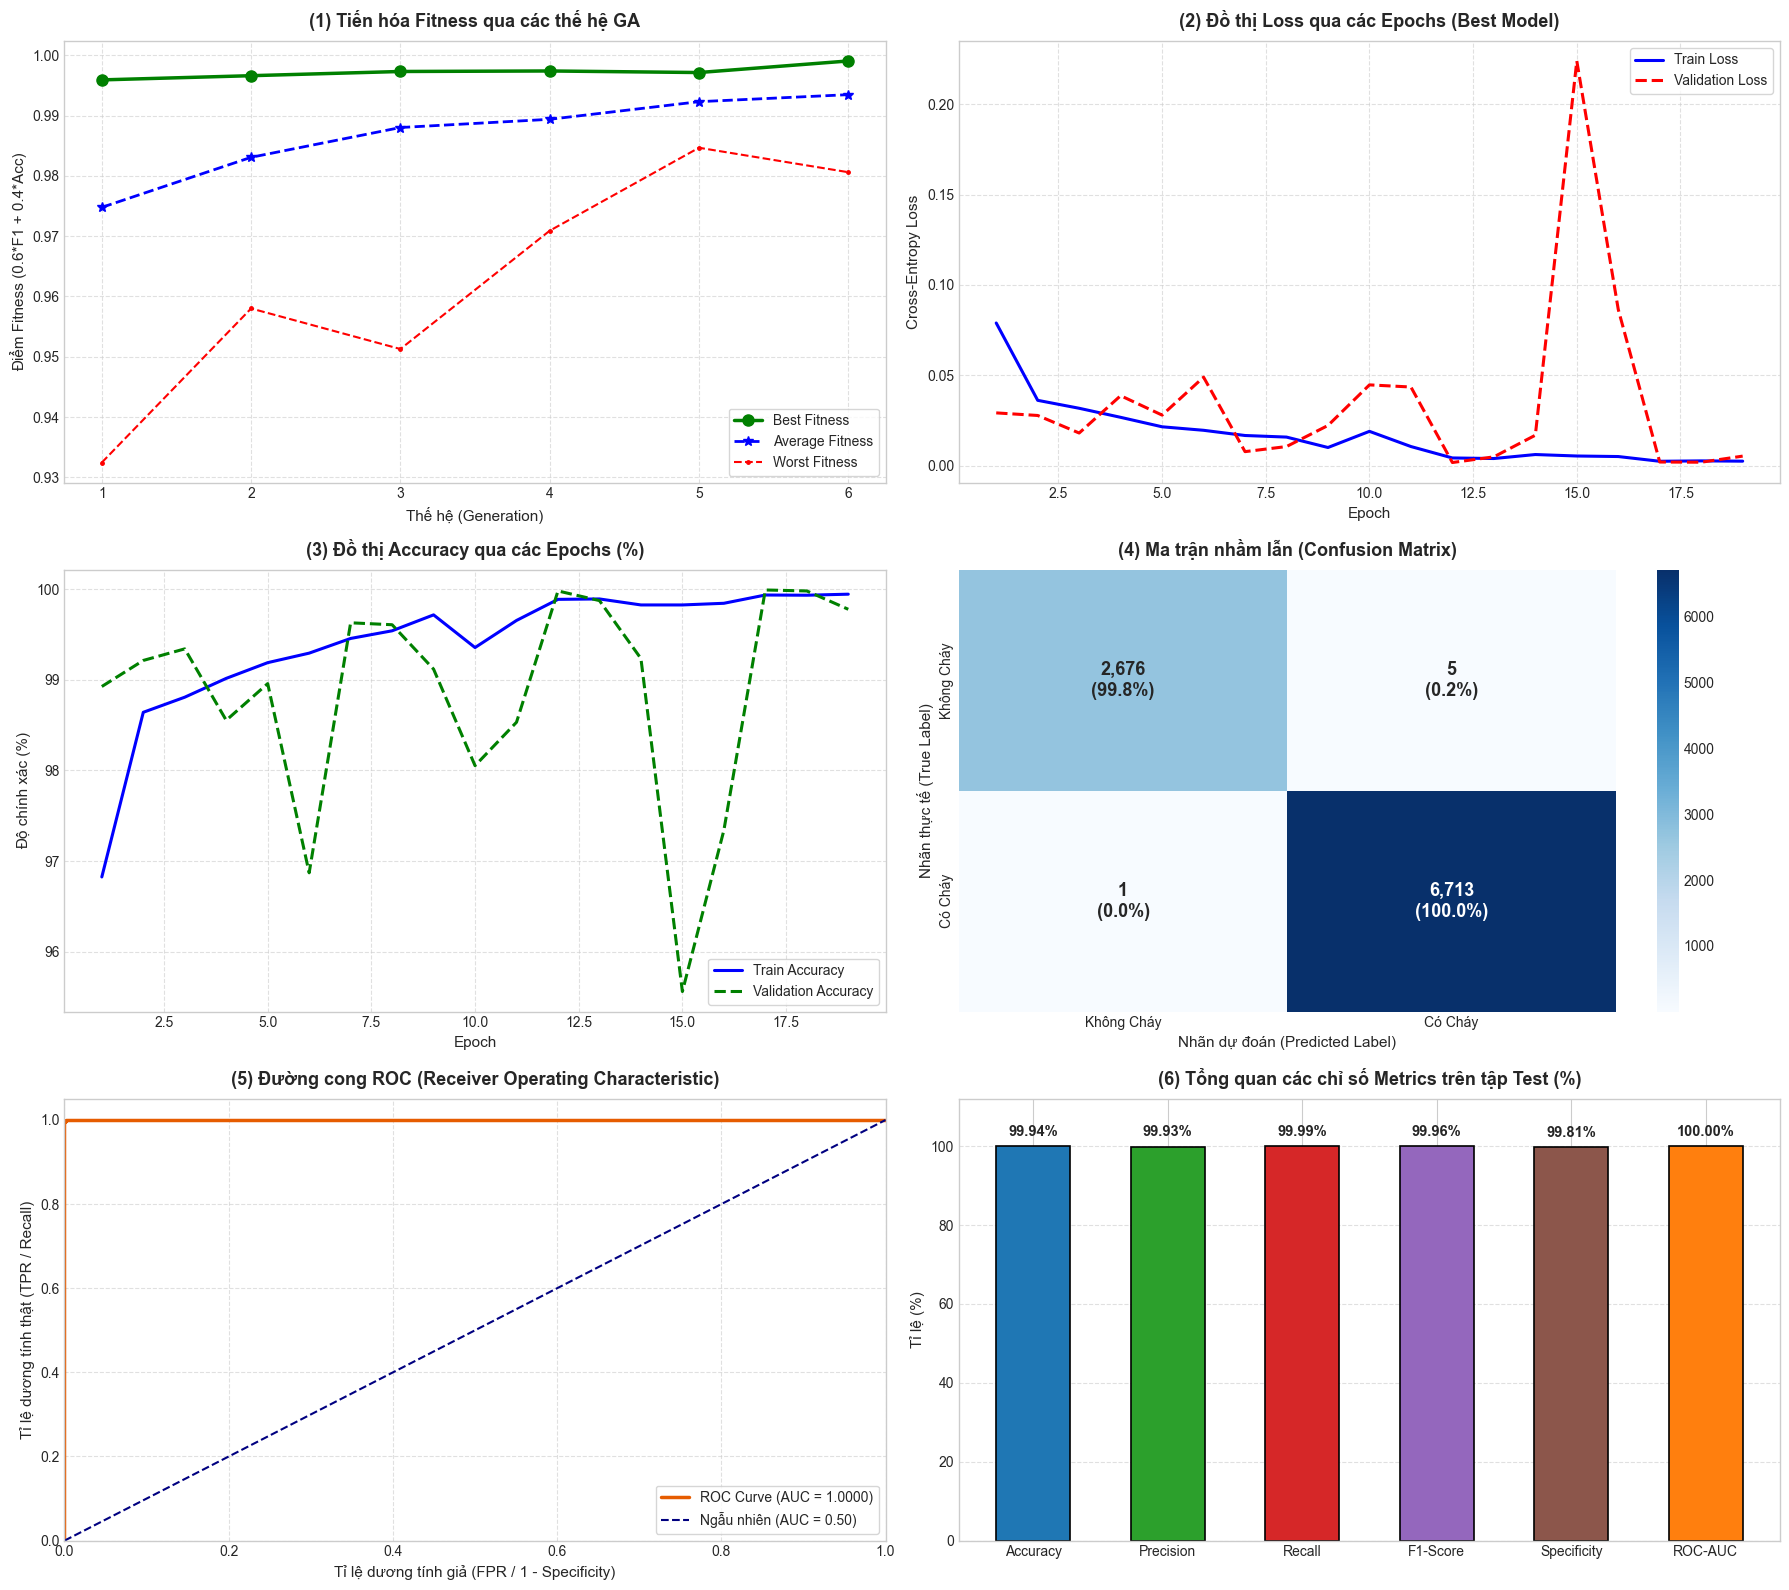

Đã lưu biểu đồ tổng thể vào file ảnh chất lượng cao: 'fire_alarm_metrics_evaluation.png'!


In [10]:
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(18, 16))

# 1. Biểu đồ tiến hóa GA
ax1 = fig.add_subplot(3, 2, 1)
gens = list(range(1, len(ga_training_history['best_fitness']) + 1))
ax1.plot(gens, ga_training_history['best_fitness'], 'go-', linewidth=2.5, markersize=8, label='Best Fitness')
ax1.plot(gens, ga_training_history['avg_fitness'], 'b*--', linewidth=2.0, markersize=7, label='Average Fitness')
ax1.plot(gens, ga_training_history['worst_fitness'], 'r.--', linewidth=1.5, markersize=5, label='Worst Fitness')
ax1.set_title('(1) Tiến hóa Fitness qua các thế hệ GA', fontsize=13, fontweight='bold', pad=10)
ax1.set_xlabel('Thế hệ (Generation)', fontsize=11)
ax1.set_ylabel('Điểm Fitness (0.6*F1 + 0.4*Acc)', fontsize=11)
ax1.set_xticks(gens)
ax1.legend(loc='lower right', frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

# 2. Đồ thị Loss qua các Epochs
ax2 = fig.add_subplot(3, 2, 2)
epochs_range = list(range(1, len(train_losses) + 1))
ax2.plot(epochs_range, train_losses, 'b-', linewidth=2.2, label='Train Loss')
ax2.plot(epochs_range, val_losses, 'r--', linewidth=2.2, label='Validation Loss')
ax2.set_title('(2) Đồ thị Loss qua các Epochs (Best Model)', fontsize=13, fontweight='bold', pad=10)
ax2.set_xlabel('Epoch', fontsize=11)
ax2.set_ylabel('Cross-Entropy Loss', fontsize=11)
ax2.legend(loc='upper right', frameon=True)
ax2.grid(True, linestyle='--', alpha=0.6)

# 3. Đồ thị Accuracy qua các Epochs
ax3 = fig.add_subplot(3, 2, 3)
ax3.plot(epochs_range, [a * 100 for a in train_accuracies], 'b-', linewidth=2.2, label='Train Accuracy')
ax3.plot(epochs_range, [a * 100 for a in val_accuracies], 'g--', linewidth=2.2, label='Validation Accuracy')
ax3.set_title('(3) Đồ thị Accuracy qua các Epochs (%)', fontsize=13, fontweight='bold', pad=10)
ax3.set_xlabel('Epoch', fontsize=11)
ax3.set_ylabel('Độ chính xác (%)', fontsize=11)
ax3.legend(loc='lower right', frameon=True)
ax3.grid(True, linestyle='--', alpha=0.6)

# 4. Ma trận nhầm lẫn (Confusion Matrix)
ax4 = fig.add_subplot(3, 2, 4)
cm_labels = ['Không Cháy', 'Có Cháy']
cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
annot_matrix = np.empty_like(cm, dtype=object)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot_matrix[i, j] = f"{cm[i, j]:,}\n({cm_percent[i, j]:.1f}%)"
sns.heatmap(
    cm, annot=annot_matrix, fmt='', cmap='Blues', cbar=True, ax=ax4,
    xticklabels=cm_labels, yticklabels=cm_labels,
    annot_kws={"size": 13, "weight": "bold"}
)
ax4.set_title('(4) Ma trận nhầm lẫn (Confusion Matrix)', fontsize=13, fontweight='bold', pad=10)
ax4.set_xlabel('Nhãn dự đoán (Predicted Label)', fontsize=11)
ax4.set_ylabel('Nhãn thực tế (True Label)', fontsize=11)

# 5. Đường cong ROC
ax5 = fig.add_subplot(3, 2, 5)
ax5.plot(fpr, tpr, color='#e65c00', lw=2.5, label=f'ROC Curve (AUC = {roc_auc_val:.4f})')
ax5.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Ngẫu nhiên (AUC = 0.50)')
ax5.set_xlim([0.0, 1.0])
ax5.set_ylim([0.0, 1.05])
ax5.set_title('(5) Đường cong ROC (Receiver Operating Characteristic)', fontsize=13, fontweight='bold', pad=10)
ax5.set_xlabel('Tỉ lệ dương tính giả (FPR / 1 - Specificity)', fontsize=11)
ax5.set_ylabel('Tỉ lệ dương tính thật (TPR / Recall)', fontsize=11)
ax5.legend(loc='lower right', frameon=True)
ax5.grid(True, linestyle='--', alpha=0.6)

# 6. Biểu đồ cột tổng hợp các chỉ số
ax6 = fig.add_subplot(3, 2, 6)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'Specificity', 'ROC-AUC']
metrics_values = [acc * 100, prec * 100, rec * 100, f1 * 100, specificity * 100, roc_auc_val * 100]
colors = ['#1f77b4', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#ff7f0e']
bars = ax6.bar(metrics_names, metrics_values, color=colors, width=0.55, edgecolor='black', linewidth=1.2)
ax6.set_title('(6) Tổng quan các chỉ số Metrics trên tập Test (%)', fontsize=13, fontweight='bold', pad=10)
ax6.set_ylabel('Tỉ lệ (%)', fontsize=11)
ax6.set_ylim([0, 112])
for bar in bars:
    h = bar.get_height()
    ax6.text(
        bar.get_x() + bar.get_width() / 2.0, h + 1.8, f'{h:.2f}%',
        ha='center', va='bottom', fontsize=10.5, fontweight='bold'
    )
ax6.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
output_img = 'fire_alarm_metrics_evaluation.png'
plt.savefig(output_img, dpi=300, bbox_inches='tight')
plt.show()
print(f"Đã lưu biểu đồ tổng thể vào file ảnh chất lượng cao: '{output_img}'!")

## 10. Bảng thông số kiến trúc tối ưu & Thử nghiệm dự đoán thực tế

In [11]:
print("=" * 80)
print("BẢNG THÔNG SỐ KIẾN TRÚC MẠNG MLP TỐI ƯU NHẤT DO GA TÌM KIẾM:")
print("=" * 80)

hidden_structure = ' -> '.join([
    str(best_mlp_chromosome[f'hidden_units_{i}'])
    for i in range(1, best_mlp_chromosome['num_layers'] + 1)
])

summary_data = [
    {"Thông số": "Số tầng ẩn (Hidden Layers)", "Giá trị": best_mlp_chromosome['num_layers']},
    {"Thông số": "Cấu trúc nơ-ron các tầng ẩn", "Giá trị": hidden_structure},
    {"Thông số": "Hàm kích hoạt (Activation)", "Giá trị": best_mlp_chromosome['activation']},
    {"Thông số": "Tỉ lệ Dropout", "Giá trị": best_mlp_chromosome['dropout']},
    {"Thông số": "Batch Normalization", "Giá trị": "Bật (True)" if best_mlp_chromosome['batch_norm'] else "Tắt (False)"},
    {"Thông số": "Thuật toán tối ưu (Optimizer)", "Giá trị": best_mlp_chromosome['optimizer'].upper()},
    {"Thông số": "Tốc độ học (Learning Rate)", "Giá trị": best_mlp_chromosome['lr']},
    {"Thông số": "Weight Decay (L2 Regularization)", "Giá trị": best_mlp_chromosome['weight_decay']},
    {"Thông số": "Kích thước Batch (Batch Size)", "Giá trị": best_mlp_chromosome['batch_size']},
    {"Thông số": "Tổng số tham số có thể học", "Giá trị": f"{count_trainable_params(best_model):,}"},
    {"Thông số": "Độ chính xác (Accuracy) trên Test set", "Giá trị": f"{acc * 100:.3f}%"},
    {"Thông số": "F1-Score trên Test set", "Giá trị": f"{f1 * 100:.3f}%"},
    {"Thông số": "Recall (Độ nhạy phát hiện cháy)", "Giá trị": f"{rec * 100:.3f}%"},
    {"Thông số": "ROC-AUC trên Test set", "Giá trị": f"{roc_auc_val:.4f}"}
]
summary_df = pd.DataFrame(summary_data)
display(summary_df)

print()
print("=" * 80)
print("THỬ NGHIỆM DỰ ĐOÁN NHANH TRÊN 5 MẪU NGẪU NHIÊN TỪ TẬP TEST:")
print("=" * 80)

sample_indices = np.random.choice(len(X_test_scaled), size=5, replace=False)
for idx in sample_indices:
    sample_input = torch.tensor(X_test_scaled[idx:idx+1], dtype=torch.float32).to(device)
    with torch.no_grad():
        out = best_model(sample_input)
        prob_fire = torch.softmax(out, dim=1)[0, 1].item()
        pred_label = out.argmax(dim=1).item()
    true_label = y_test[idx]
    
    true_str = "CÓ CHÁY [1]" if true_label == 1 else "KHÔNG CHÁY [0]"
    pred_str = "CÓ CHÁY [1]" if pred_label == 1 else "KHÔNG CHÁY [0]"
    is_correct = "CHÍNH XÁC" if pred_label == true_label else "KHÔNG CHÍNH XÁC"
    
    print(f"Mẫu #{idx:05d} | Thực tế: {true_str:<15} | Dự đoán: {pred_str:<15} "
          f"(Xác suất cháy: {prob_fire*100:6.2f}%) | Kết quả: {is_correct}")

BẢNG THÔNG SỐ KIẾN TRÚC MẠNG MLP TỐI ƯU NHẤT DO GA TÌM KIẾM:


,Thông số,Giá trị
0,Số tầng ẩn (Hidden Layers),4
1,Cấu trúc nơ-ron các tầng ẩn,512 -> 128 -> 32 -> 64
2,Hàm kích hoạt (Activation),relu
3,Tỉ lệ Dropout,0.0
4,Batch Normalization,Bật (True)
5,Thuật toán tối ưu (Optimizer),ADAMW
6,Tốc độ học (Learning Rate),0.003
7,Weight Decay (L2 Regularization),0.0
8,Kích thước Batch (Batch Size),256
9,Tổng số tham số có thể học,"80,162"



THỬ NGHIỆM DỰ ĐOÁN NHANH TRÊN 5 MẪU NGẪU NHIÊN TỪ TẬP TEST:
Mẫu #02221 | Thực tế: CÓ CHÁY [1]     | Dự đoán: CÓ CHÁY [1]     (Xác suất cháy: 100.00%) | Kết quả: CHÍNH XÁC
Mẫu #08296 | Thực tế: CÓ CHÁY [1]     | Dự đoán: CÓ CHÁY [1]     (Xác suất cháy:  99.94%) | Kết quả: CHÍNH XÁC
Mẫu #01731 | Thực tế: CÓ CHÁY [1]     | Dự đoán: CÓ CHÁY [1]     (Xác suất cháy:  99.99%) | Kết quả: CHÍNH XÁC
Mẫu #02609 | Thực tế: CÓ CHÁY [1]     | Dự đoán: CÓ CHÁY [1]     (Xác suất cháy: 100.00%) | Kết quả: CHÍNH XÁC
Mẫu #07352 | Thực tế: CÓ CHÁY [1]     | Dự đoán: CÓ CHÁY [1]     (Xác suất cháy: 100.00%) | Kết quả: CHÍNH XÁC


## 11. Xuất mô hình PyTorch TorchScript (JIT) sẵn sàng triển khai trên Raspberry Pi 5

Để triển khai mô hình trên vi máy tính **Raspberry Pi 5** một cách đơn giản, ổn định và không cần cài đặt các backend phức tạp như XNNPACK/ExecuTorch:
1. **TorchScript (`torch.jit.trace`)**: Đóng gói toàn bộ cấu trúc mạng và trọng số vào 1 file nhị phân duy nhất (`fire_alarm_model_jit.pt`). Trên Pi 5 chỉ cần cài `torch` và dùng `torch.jit.load()`, không cần file định nghĩa class mạng.
2. **Bộ thông số chuẩn hóa (`scaler_params.json`)**: Lưu giá trị mean và scale của 12 cảm biến để chuẩn hóa trực tiếp dữ liệu thô đọc từ cảm biến IoT trên Pi 5.
3. **Hiệu năng trên Pi 5**: Mạng MLP nhỏ gọn (80k tham số) đạt tốc độ suy luận dưới **0.5 ms/mẫu** (~2,000 FPS) trên CPU ARM Cortex-A76 của Pi 5.


In [10]:
# ==============================================================================
# XUẤT MÔ HÌNH PYTORCH TORCHSCRIPT (JIT) SẴN SÀNG TRIỂN KHAI TRÊN RASPBERRY PI 5
# ==============================================================================
import json
import copy
import torch

# 1. Chuyển mô hình về CPU để tương thích hoàn toàn với kiến trúc ARM của Raspberry Pi
model_cpu = copy.deepcopy(best_model).to('cpu')
model_cpu.eval()

# 2. Trace mô hình sang định dạng TorchScript JIT (.pt)
dummy_input = torch.randn(1, len(feature_cols), dtype=torch.float32)
traced_jit_model = torch.jit.trace(model_cpu, dummy_input)
jit_model_path = 'fire_alarm_model_jit.pt'
traced_jit_model.save(jit_model_path)
print(f'[OK] Đã xuất thành công mô hình TorchScript vào: "{jit_model_path}"')

# 3. Xuất thông số chuẩn hóa StandardScaler sang scaler_params.json
scaler_info = {
    'features': feature_cols,
    'mean': scaler.mean_.tolist(),
    'scale': scaler.scale_.tolist()
}
scaler_path = 'scaler_params.json'
with open(scaler_path, 'w', encoding='utf-8') as f:
    json.dump(scaler_info, f, indent=4)
print(f'[OK] Đã xuất thông số chuẩn hóa cảm biến vào: "{scaler_path}"')

# 4. Kiểm chứng độ chính xác tương đương giữa PyTorch gốc và TorchScript JIT
with torch.no_grad():
    original_out = model_cpu(dummy_input)
    reloaded_jit = torch.jit.load(jit_model_path)
    jit_out = reloaded_jit(dummy_input)

max_diff = (original_out - jit_out).abs().max().item()
print(f'[OK] Sai số đầu ra giữa PyTorch và TorchScript: {max_diff:.8f}')
assert max_diff < 1e-5, 'Đầu ra không khớp!'
print('[OK] Kiểm chứng thành công: Mô hình đã sẵn sàng để copy sang Raspberry Pi 5 chạy bằng script infer_pi5.py!')


[OK] Đã xuất thành công mô hình TorchScript vào: "fire_alarm_model_jit.pt"
[OK] Đã xuất thông số chuẩn hóa cảm biến vào: "scaler_params.json"
[OK] Sai số đầu ra giữa PyTorch và TorchScript: 0.00000000
[OK] Kiểm chứng thành công: Mô hình đã sẵn sàng để copy sang Raspberry Pi 5 chạy bằng script infer_pi5.py!
